# HW01

- 1. 실습코드00 (Lab00_ImageLoad): ITK-SNAP으로 day15를 day0에 registration한 결과 비교
- 2. 실습코드01 (Lab02_LinearFiltering) Exercise 1: local histogram equalization으로 숨겨진 기호 확인
- 3. Exercise 2: 본인 사진(grayscale)에 대한 kernel size별 box LPF 결과 및 연산시간 비교
- 4. Exercise 3: blurred image에 Laplacian HPF 결과를 이용한 sharpening

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
from skimage import io
from skimage.util import img_as_float   # 사진을 항상 0~1 float로 통일

### 데이터 경로
Colab에서 실행하는 경우 Google Drive를 마운트하고, 수업과 같은 폴더 구조를 사용합니다. 로컬에서 실행하면 마운트 셀은 건너뛰고 경로만 바꾸면 됩니다.

In [13]:
from google.colab import drive
drive.mount('/content/drive')
import glob, os
print(glob.glob('/content/drive/MyDrive/class/DIP1/**/hidden-symbols.tif', recursive=True))
print(sorted(os.listdir('/content/drive/MyDrive/class/DIP1/covid_ct')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['/content/drive/MyDrive/class/DIP1/DIP4E/DIP4E/hidden-symbols.tif']
['volume-covid19-A-0700_day000.nii.gz', 'volume-covid19-A-0700_day015-reg_to_day000.nii.gz', 'volume-covid19-A-0700_day015.nii.gz']


In [14]:
imgpath = '/content/drive/MyDrive/class/DIP1/DIP4E/DIP4E'     # ← 이것만 변경
ctpath  = '/content/drive/MyDrive/class/DIP1/covid_ct'

CT_DAY0    = os.path.join(ctpath, 'volume-covid19-A-0700_day000.nii.gz')
CT_DAY15   = os.path.join(ctpath, 'volume-covid19-A-0700_day015.nii.gz')
CT_DAY15_R = os.path.join(ctpath, 'volume-covid19-A-0700_day015-reg_to_day000.nii.gz')

HIDDEN     = os.path.join(imgpath, 'hidden-symbols.tif')
MY_PHOTO   = '/content/drive/MyDrive/class/my_photo.jpg'      # Drive에 올린 위치로
MY_BLURRED = '/content/drive/MyDrive/class/my_blurred.jpg'

---
## 1. 실습코드00 — day15 → day0 registration 결과 비교

### ITK-SNAP에서 registration 결과 파일 만들기
1. `File > Open Main Image` → `..._day000.nii.gz` (fixed image)
2. `File > Add Another Image` → `..._day015.nii.gz` (moving image)
3. `Tools > Registration` → **Automatic** 탭에서 Transformation model을 Rigid(필요 시 Affine)로, Image similarity metric은 Mutual information으로 두고 `Run Registration`
4. 결과를 보고 필요하면 **Manual** 탭에서 회전·이동 미세조정
5. Registration 패널 하단의 **Reslice** 아이콘 클릭 → day0 격자로 재샘플된 새 레이어 생성
6. 생성된 레이어를 `File > Save Image`로 `volume-covid19-A-0700_day015-reg_to_day000.nii.gz`로 저장

Reslice 단계를 거쳐야 두 영상의 shape과 voxel 격자가 같아져서, 같은 slice index가 같은 해부학적 위치를 가리킵니다.

In [15]:
import nibabel as nib

h0, h15, h15r = nib.load(CT_DAY0), nib.load(CT_DAY15), nib.load(CT_DAY15_R)
ct_base   = h0.get_fdata()
ct_FU     = h15.get_fdata()
ct_FU_reg = h15r.get_fdata()

for name, h in [('day000', h0), ('day015', h15), ('day015-reg', h15r)]:
    print(f'{name:11s} shape={h.shape}  voxel={tuple(float(round(v, 3)) for v in h.header.get_zooms())}')
print('day000 vs day015-reg 격자 일치:', ct_base.shape == ct_FU_reg.shape and np.allclose(h0.affine, h15r.affine, atol=1e-3))

day000      shape=(512, 512, 70)  voxel=(0.7400000095367432, 0.7400000095367432, 5.0)
day015      shape=(512, 512, 67)  voxel=(0.7400000095367432, 0.7400000095367432, 5.0)
day015-reg  shape=(512, 512, 70)  voxel=(0.7400000095367432, 0.7400000095367432, 5.0)
day000 vs day015-reg 격자 일치: True


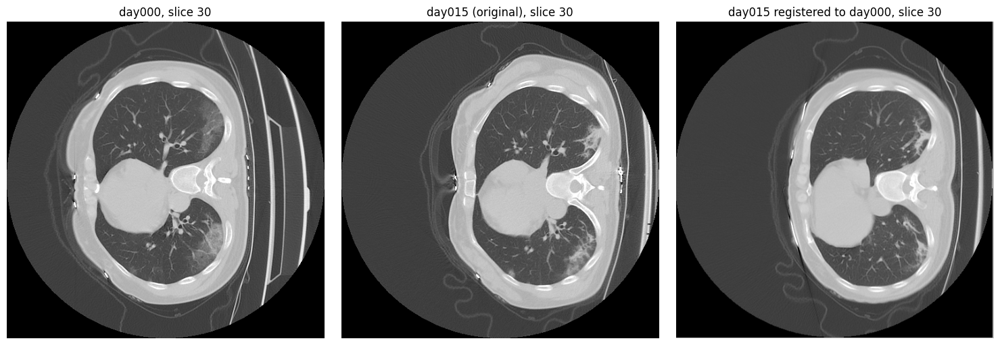

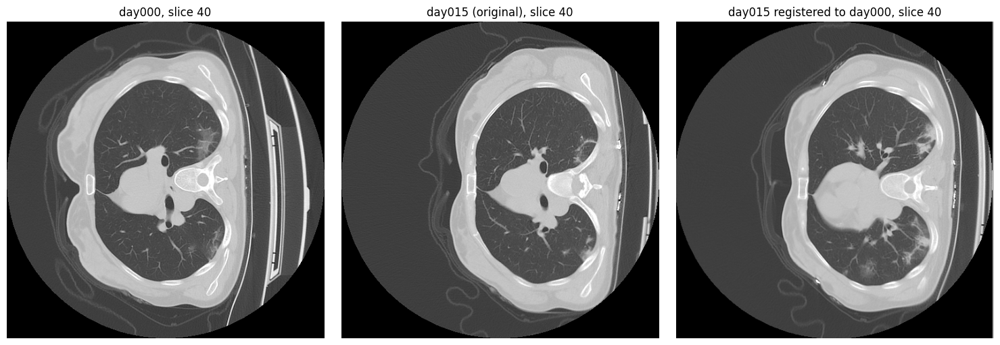

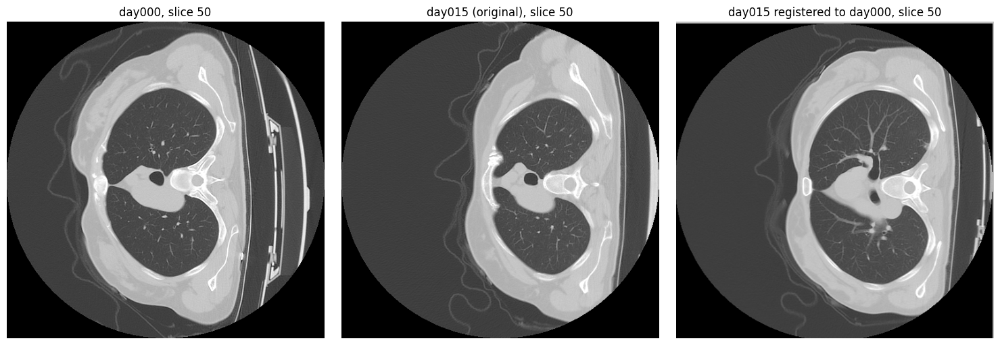

In [16]:
def show_three(z, vmin=-1500, vmax=500):
    plt.figure(figsize=(15, 5))
    for k, (im, t) in enumerate([(ct_base, 'day000'), (ct_FU, 'day015 (original)'),
                                  (ct_FU_reg, 'day015 registered to day000')], 1):
        plt.subplot(1, 3, k)
        if z < im.shape[2]:
            plt.imshow(im[:, :, z], vmin=vmin, vmax=vmax, cmap='gray')
        plt.title(f'{t}, slice {z}'); plt.axis('off')
    plt.tight_layout(); plt.show()

for z in [30, 40, 50]:
    show_three(z)

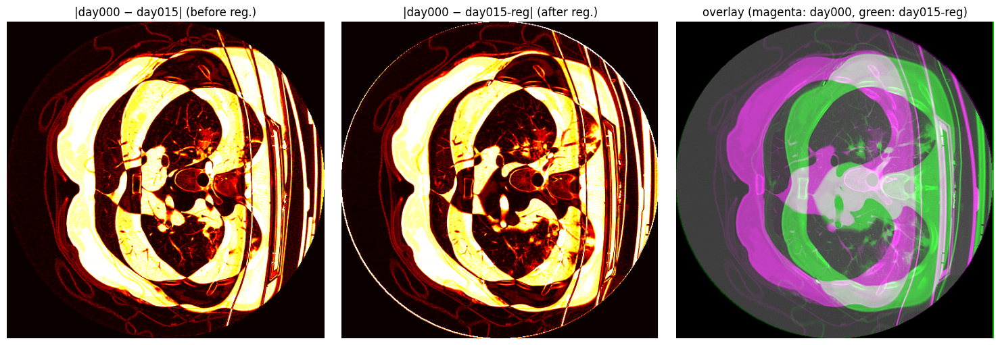

mean |diff| before: 329.9  after: 333.2


In [17]:
z = 40
a = ct_base[:, :, z]
b = ct_FU[:a.shape[0], :a.shape[1], z] if z < ct_FU.shape[2] else np.zeros_like(a)
c = ct_FU_reg[:, :, z]
a_ = a[:b.shape[0], :b.shape[1]]

plt.figure(figsize=(15, 5))
plt.subplot(131); plt.imshow(np.abs(a_ - b), vmin=0, vmax=1000, cmap='hot'); plt.title('|day000 − day015| (before reg.)'); plt.axis('off')
plt.subplot(132); plt.imshow(np.abs(a - c), vmin=0, vmax=1000, cmap='hot'); plt.title('|day000 − day015-reg| (after reg.)'); plt.axis('off')
norm = lambda x: np.clip((x + 1500) / 2000, 0, 1)
plt.subplot(133); plt.imshow(np.dstack([norm(a), norm(c), norm(a)])); plt.title('overlay (magenta: day000, green: day015-reg)'); plt.axis('off')
plt.tight_layout(); plt.show()

print('mean |diff| before:', np.mean(np.abs(a_ - b)).round(1), ' after:', np.mean(np.abs(a - c)).round(1))

**결과 해석**
- registration 전에는 촬영 시 환자 자세·위치가 달라 같은 slice index라도 서로 다른 해부학적 위치가 나타나며, 차영상에서 폐·흉벽 경계를 따라 큰 오차가 보인다.
- registration 후에는 흉곽 윤곽과 주요 구조물이 정렬되어 경계 부위 오차가 줄어들고, 남은 차이는 주로 폐 실질 내부의 변화(병변의 범위·음영 변화)를 반영한다.
- 0일차에 비해 15일차의 폐 부피가 줄어들었다.

---
## 2. Exercise 1 — Local histogram equalization

- 적절한 neighborhood size N을 찾아 숨겨진 기호를 모두 확인한다.
- `vmax=255`로 고정하고 histogram processing만으로 기호를 드러낸다.

(256, 256) uint8


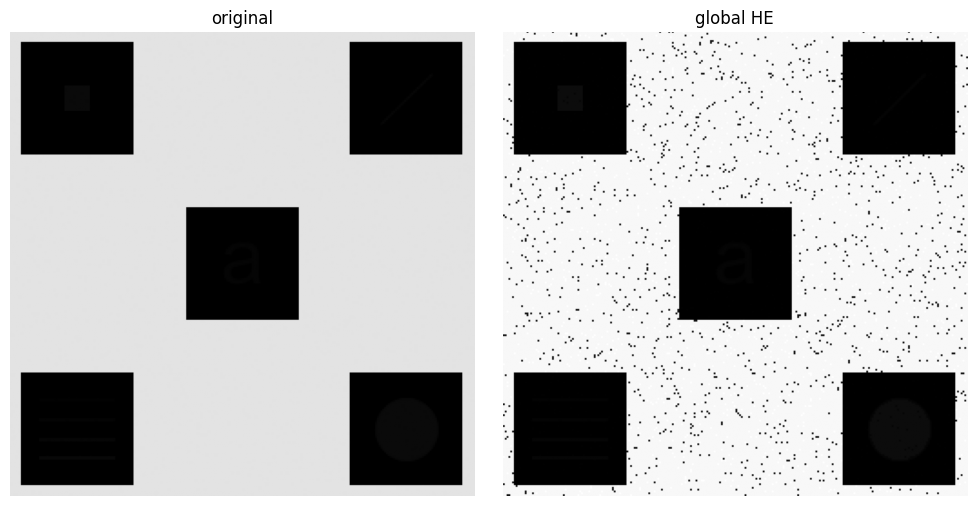

In [18]:
f = plt.imread(HIDDEN)
if f.ndim == 3: f = f[..., 0]
f = f.astype(np.uint8)
print(f.shape, f.dtype)

def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0, 256])
    cdf = histogram.cumsum()
    cdf_min = cdf[cdf > 0].min()          # 0이 아닌 첫 cdf 값 사용
    cdf_max = cdf.max()
    if cdf_max == cdf_min:                # 블록 전체가 한 가지 값이면 변환 불가 → 그대로 반환
        return image.copy()
    cdf_normalized = np.clip((cdf - cdf_min) * 255 / (cdf_max - cdf_min), 0, 255)
    return cdf_normalized.astype(np.uint8)[image]

plt.figure(figsize=(10, 5))
plt.subplot(121); plt.imshow(f, vmin=0, vmax=255, cmap='gray'); plt.title('original'); plt.axis('off')
plt.subplot(122); plt.imshow(histogram_equalization(f), vmin=0, vmax=255, cmap='gray'); plt.title('global HE'); plt.axis('off')
plt.tight_layout(); plt.show()

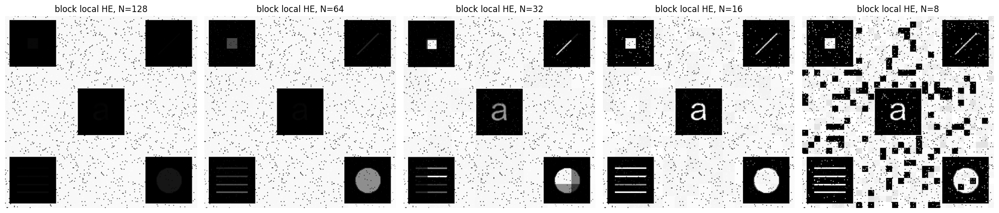

In [19]:
def local_he_block(f, N):
    out = np.zeros_like(f)
    for x in np.arange(0, f.shape[0], N):
        for y in np.arange(0, f.shape[1], N):
            out[x:x+N, y:y+N] = histogram_equalization(f[x:x+N, y:y+N])
    return out

Ns = [128, 64, 32, 16, 8]
plt.figure(figsize=(20, 4.5))
for k, N in enumerate(Ns, 1):
    plt.subplot(1, len(Ns), k)
    plt.imshow(local_he_block(f, N), vmin=0, vmax=255, cmap='gray')
    plt.title(f'block local HE, N={N}'); plt.axis('off')
plt.tight_layout(); plt.show()

블록 방식은 블록 경계에서 밝기가 불연속(바둑판 무늬)해지고, 기호가 블록 경계에 걸리면 잘려 보입니다. 교재(Gonzalez)의 원래 방식처럼 **각 픽셀을 중심으로 N×N 창을 이동(sliding window)**하며 중심 픽셀만 변환하면 경계 문제가 없습니다.

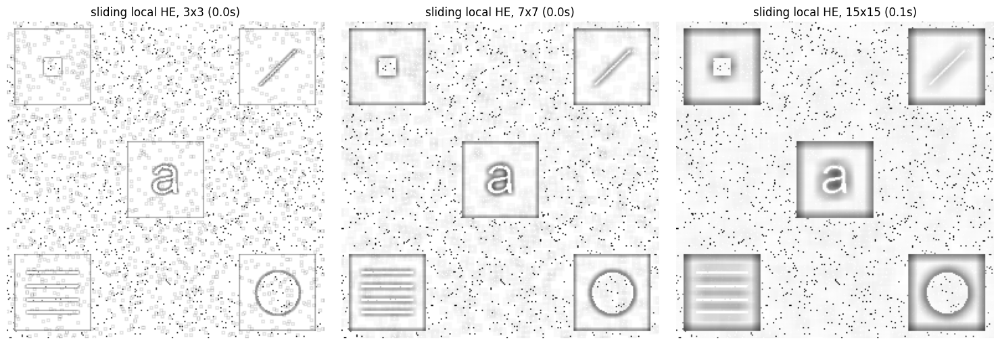

In [20]:
from numpy.lib.stride_tricks import sliding_window_view

def local_he_sliding(f, N):
    # N은 홀수. 각 픽셀 중심 N×N 창 안에서 '중심값 이하인 픽셀 비율'(= 중심 픽셀의 CDF)을 0~255로 매핑
    r = N // 2
    fp = np.pad(f, r, mode='reflect')
    out = np.zeros_like(f)
    for i0 in range(0, f.shape[0], 64):          # 메모리 절약을 위해 64행씩 처리
        i1 = min(i0 + 64, f.shape[0])
        win = sliding_window_view(fp[i0:i1 + 2*r], (N, N))   # (rows, cols, N, N)
        center = f[i0:i1, :, None, None]
        out[i0:i1] = (255 * np.mean(win <= center, axis=(2, 3))).astype(np.uint8)
    return out

plt.figure(figsize=(15, 5))
for k, N in enumerate([3, 7, 15], 1):
    t0 = time.time(); g = local_he_sliding(f, N)
    plt.subplot(1, 3, k); plt.imshow(g, vmin=0, vmax=255, cmap='gray')
    plt.title(f'sliding local HE, {N}x{N} ({time.time()-t0:.1f}s)'); plt.axis('off')
plt.tight_layout(); plt.show()

**결과 해석**
- Global HE는 영상 전체 히스토그램 기준으로 변환한다. 숨은 기호와 주변 배경은 밝기 차이가 매우 작고 면적도 작아서 전체 히스토그램에 거의 영향을 주지 않으므로, global HE 후에도 기호가 드러나지 않는다.
- Local HE는 작은 영역 안의 히스토그램만으로 변환하므로, 그 영역 안의 미세한 밝기 차이(배경 vs 기호)가 0~255 범위로 크게 늘어나 기호가 보인다.
- N이 크면 global HE와 비슷해져 기호가 보이지 않고, N이 너무 작으면 노이즈까지 증폭된다. N=7에서 5개 기호가 모두 가장 선명했다. N=3은 윤곽선만 보이고 노이즈가 커졌으며, N=15는 7×7의 대각선이 흐려지고 상자 주변에 halo가 생겨 오히려 나빠졌다

---
## 3. Exercise 2 — 본인 사진 box LPF (kernel size 3, 7, 15, 30) 및 연산시간

In [21]:
f = img_as_float(io.imread(MY_PHOTO, as_gray=True))
print('original:', f.shape, f.dtype)
# 원본이 크면 convolve2d가 매우 느리므로 긴 변을 ~800px로 축소 (수업 예제의 [::2,::2]와 같은 방식)
step = max(1, int(np.ceil(max(f.shape) / 800)))
f = f[::step, ::step]
print('used    :', f.shape, f.dtype)

original: (1344, 1782) float64
used    : (448, 594) float64


N= 3  computation time = 0.017 sec


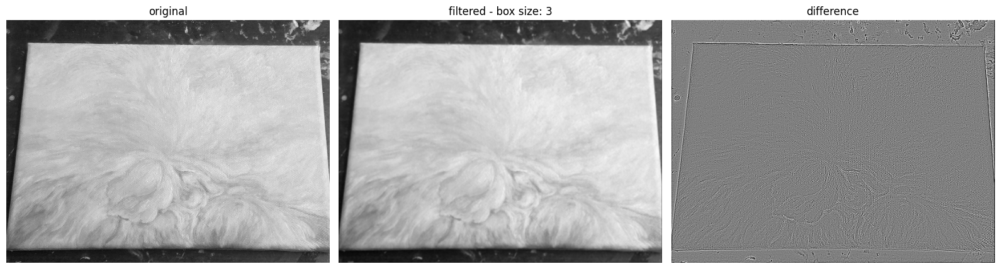

N= 7  computation time = 0.033 sec


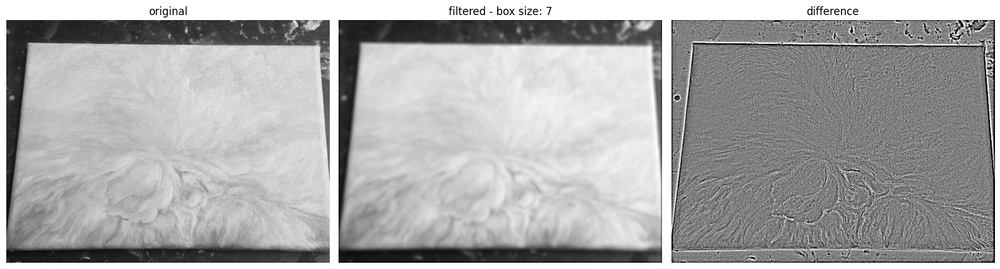

N=15  computation time = 0.132 sec


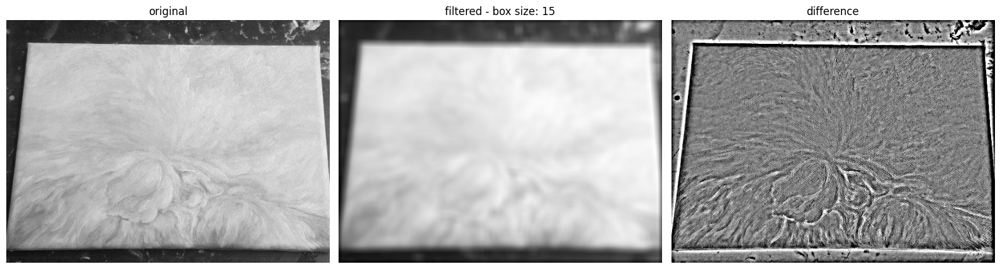

N=30  computation time = 0.458 sec


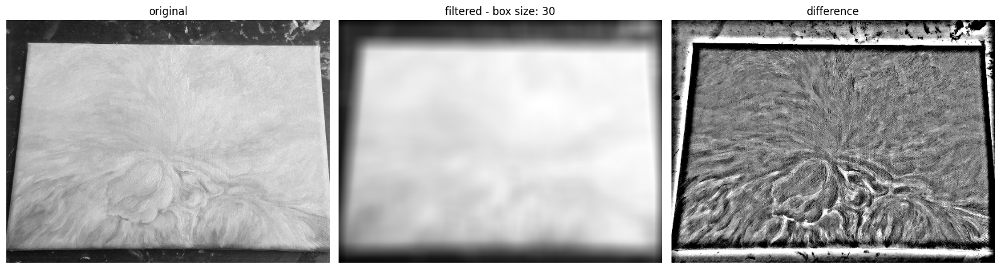

In [22]:
times = []
for N in np.array([3, 7, 15, 30]):
    wb = np.ones((N, N))
    wb = wb / np.sum(wb)
    s0 = time.time()
    y_b = signal.convolve2d(f, wb, mode='same')
    compu_time = time.time() - s0
    times.append(compu_time)
    print(f'N={N:2d}  computation time = {compu_time:.3f} sec')

    plt.figure(figsize=(16, 6))
    plt.subplot(1, 3, 1); plt.imshow(f, cmap='gray'); plt.axis('off'); plt.title('original')
    plt.subplot(1, 3, 2); plt.imshow(y_b, cmap='gray'); plt.axis('off'); plt.title(f'filtered - box size: {N}')
    plt.subplot(1, 3, 3); plt.imshow(y_b - f, cmap='gray', vmin=-.1, vmax=.1); plt.axis('off'); plt.title('difference')
    plt.tight_layout(); plt.show()

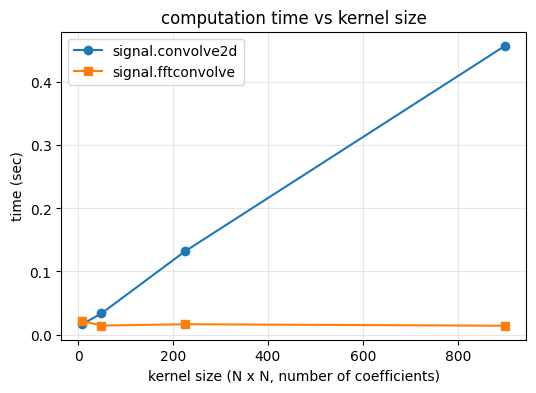

In [23]:
# kernel size에 따른 연산시간: 직접 convolution vs FFT 기반 convolution
Ns = np.array([3, 7, 15, 30])
t_fft = []
for N in Ns:
    wb = np.ones((N, N)) / N**2
    s0 = time.time(); signal.fftconvolve(f, wb, mode='same'); t_fft.append(time.time() - s0)

plt.figure(figsize=(6, 4))
plt.plot(Ns**2, times, 'o-', label='signal.convolve2d')
plt.plot(Ns**2, t_fft, 's-', label='signal.fftconvolve')
plt.xlabel('kernel size (N x N, number of coefficients)'); plt.ylabel('time (sec)')
plt.legend(); plt.grid(alpha=.3); plt.title('computation time vs kernel size'); plt.show()

**결과 해석**
- box kernel이 커질수록 더 넓은 영역을 평균하므로 cut-off 주파수가 낮아져 영상이 더 흐려지고, difference 영상에서 edge·texture(고주파 성분)가 더 많이 제거된 것이 보인다.
- 직접 convolution은 출력 픽셀마다 N² 번의 곱셈·덧셈이 필요하므로 연산시간이 대략 N²에 비례해 증가한다.
- FFT 기반 convolution은 kernel 크기와 거의 무관하게 일정한 시간이 걸려서, 큰 kernel에서는 훨씬 빠르다.
- (작성) 본인 사진에서 각 N별로 어떤 디테일이 사라졌는지.

---
## 4. Exercise 3 — Laplacian HPF를 이용한 sharpening

중심계수가 양수인 Laplacian kernel(`w2`, `w4`)로 HPF 결과 `y`를 구하고 `g = f + c·y`로 sharpening한다. (중심계수가 음수인 `w1`, `w3`를 쓰면 `g = f − c·y`)
w(4-이웃 / 8-이웃)와 c를 바꿔가며 결과를 비교한다.

In [24]:
f = img_as_float(io.imread(MY_BLURRED, as_gray=True))   # 0~1 범위
step = max(1, int(np.ceil(max(f.shape) / 800)))
f = f[::step, ::step]
print(f.shape, f.dtype, f.min(), f.max())

w2 = np.array([[0, -1, 0], [-1, 4., -1], [0, -1, 0]])        # 4-이웃
w4 = np.array([[-1, -1, -1], [-1, 8., -1], [-1, -1, -1]])    # 8-이웃 (대각 포함)

(600, 800) float64 0.0008333333333333333 1.0


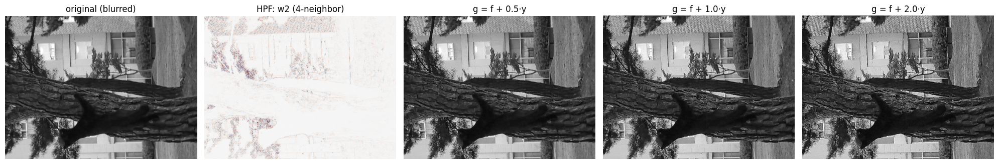

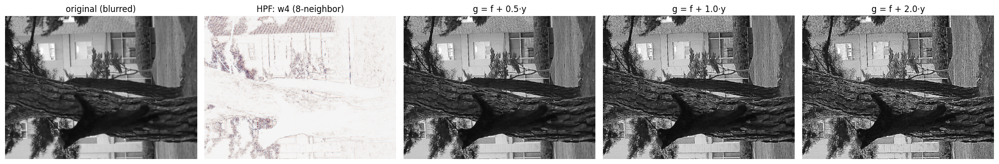

In [25]:
cs = [0.5, 1.0, 2.0]
for w, wname in [(w2, 'w2 (4-neighbor)'), (w4, 'w4 (8-neighbor)')]:
    y = signal.convolve2d(f, w, mode='same', boundary='symm')
    plt.figure(figsize=(20, 5))
    plt.subplot(1, len(cs) + 2, 1); plt.imshow(f, cmap='gray', vmin=0, vmax=1); plt.axis('off'); plt.title('original (blurred)')
    plt.subplot(1, len(cs) + 2, 2)
    plt.imshow(y, cmap='RdBu_r', vmin=-0.5*np.max(np.abs(y)), vmax=0.5*np.max(np.abs(y)))
    plt.axis('off'); plt.title(f'HPF: {wname}')
    for k, c in enumerate(cs, 3):
        g = np.clip(f + c * y, 0, 1)
        plt.subplot(1, len(cs) + 2, k); plt.imshow(g, cmap='gray', vmin=0, vmax=1); plt.axis('off'); plt.title(f'g = f + {c}·y')
    plt.tight_layout(); plt.show()

In [26]:
# 선명도 정량 비교: Laplacian 응답의 분산 (값이 클수록 edge가 강함)
def sharpness(im):
    return np.var(signal.convolve2d(im, w2, mode='same', boundary='symm'))

print(f'{"original":22s} sharpness = {sharpness(f):.5f}')
for w, wname in [(w2, 'w2'), (w4, 'w4')]:
    y = signal.convolve2d(f, w, mode='same', boundary='symm')
    for c in cs:
        print(f'{wname}, c={c:<4}            sharpness = {sharpness(np.clip(f + c*y, 0, 1)):.5f}')

original               sharpness = 0.03323
w2, c=0.5             sharpness = 0.28342
w2, c=1.0             sharpness = 0.54178
w2, c=2.0             sharpness = 0.95534
w4, c=0.5             sharpness = 0.46672
w4, c=1.0             sharpness = 0.79128
w4, c=2.0             sharpness = 1.25837


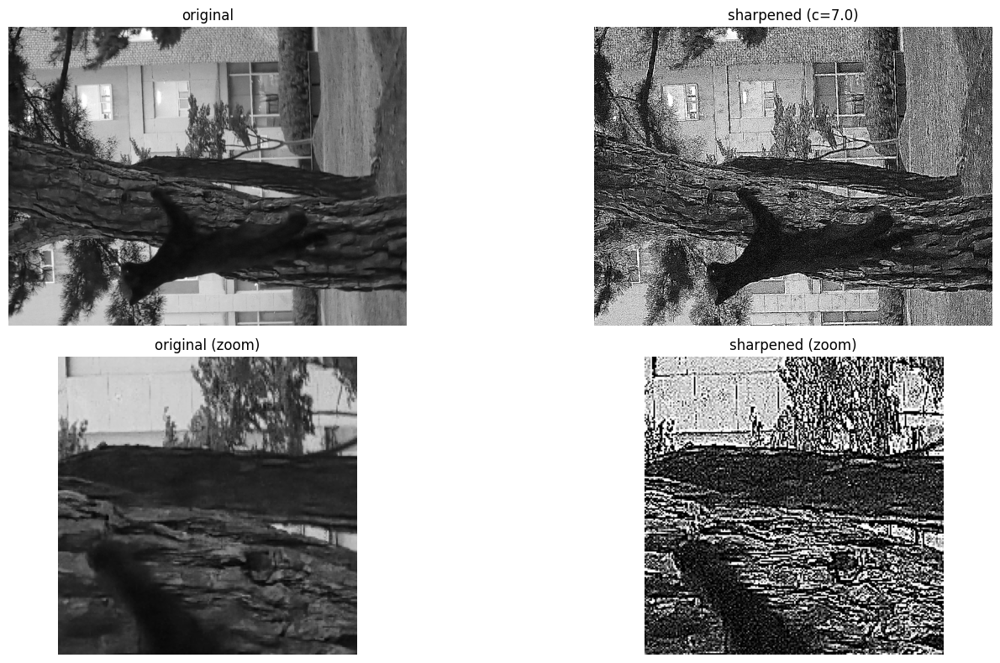

In [63]:
w_best, c_best = w2, 7.0
y = signal.convolve2d(f, w_best, mode='same', boundary='symm')
g = np.clip(f + c_best * y, 0, 1)

H, W = f.shape; s = min(H, W) // 3; y0, x0 = H // 3, W // 3
plt.figure(figsize=(16, 8))
plt.subplot(221); plt.imshow(f, cmap='gray', vmin=0, vmax=1); plt.axis('off'); plt.title('original')
plt.subplot(222); plt.imshow(g, cmap='gray', vmin=0, vmax=1); plt.axis('off'); plt.title(f'sharpened (c={c_best})')
plt.subplot(223); plt.imshow(f[y0:y0+s, x0:x0+s], cmap='gray', vmin=0, vmax=1); plt.axis('off'); plt.title('original (zoom)')
plt.subplot(224); plt.imshow(g[y0:y0+s, x0:x0+s], cmap='gray', vmin=0, vmax=1); plt.axis('off'); plt.title('sharpened (zoom)')
plt.tight_layout(); plt.show()

**결과 해석**
- Laplacian은 2차 미분 연산자로, 밝기가 급변하는 edge 부근에서 큰 값을 가지고 평탄한 영역에서는 0에 가깝다. 이 HPF 결과를 원본에 더하면 edge 양쪽의 밝기 차이가 커져서 선명해 보인다.
- 8-이웃 kernel(w4)은 대각 방향 변화까지 반영하므로 같은 c에서 효과가 더 강하다.
- c가 너무 크면 edge 주변에 halo(overshoot)가 생기고 노이즈가 함께 증폭된다.
- W = 7, C = 0에서 가장 고양이가 선명하게 보였다. 다만 배경에 노이즈가 생겼기 때문에 고양이를 오려두고 matrix를 빼는 연산을 하여 보정할 수 있을 것 같아 보인다.